# 02 - Data Cleaning and Exploratory Analysis

**Phases 2 and 3.** Apply the cleaning rules decided in notebook 01, then
explore the clean data to understand the customer base.

Every chart here answers a question that matters to the retention problem.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
import config
from data_processing import load_raw, clean, load_clean, load_cancellations

## 1. Cleaning

The rules, and why each one exists:

| Rule | Reason |
|---|---|
| Drop exact duplicate rows | Same product, invoice, time and price repeated - a data artefact |
| Separate cancellations | Not sales, but the behaviour is kept as a feature |
| Drop rows without `CustomerID` | Cannot be attributed to a customer |
| Drop quantity <= 0 | Stock adjustments and write-offs |
| Drop unit price <= 0 | Free items and data entry errors |
| Drop admin stock codes | Bank charges, fees, discounts - not product purchases |

Nothing is deleted silently: the step-by-step record loss is printed below.

In [2]:
raw = load_raw()
clean_df, cancellations, log = clean(raw)

Cleaning 541,909 raw rows


  drop exact duplicates              rows=536,641  removed= 5,268  


  separate cancellations             rows=527,390  removed= 9,251  9,251 cancelled lines kept for features
  drop missing CustomerID            rows=392,732  removed=134,658  unattributed revenue GBP 1,732,778
  drop quantity <= 0                 rows=392,732  removed=     0  
  drop unit price <= 0               rows=392,692  removed=    40  


  drop admin stock codes             rows=392,398  removed=   294  bank charges, fees, discounts, manual adj.


  FINAL                              rows=392,398  retained=72.4% of raw  customers=4,334


In [3]:
log

,step,rows_after,rows_removed,note
0,drop exact duplicates,536641,5268,
1,separate cancellations,527390,9251,"9,251 cancelled lines kept for features"
2,drop missing CustomerID,392732,134658,"unattributed revenue GBP 1,732,778"
3,drop quantity <= 0,392732,0,
4,drop unit price <= 0,392692,40,
5,drop admin stock codes,392398,294,"bank charges, fees, discounts, manual adj."


The largest loss is the 134,658 rows with no `CustomerID`, carrying about
GBP 1.73m of revenue. That revenue is real, but it cannot be assigned to a
customer, so it is excluded from customer-level analysis and reported as a
known limitation rather than ignored.

In [4]:
clean_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,InvoiceDay
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12-01
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12-01
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12-01
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12-01
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12-01


## 2. How big is the business, and how loyal is the customer base?

In [5]:
df = load_clean()
orders = df.groupby('CustomerID').InvoiceNo.nunique()
rev_by_cust = df.groupby('CustomerID').Revenue.sum()

print(f'customers        : {df.CustomerID.nunique():,}')
print(f'orders           : {df.InvoiceNo.nunique():,}')
print(f'revenue          : GBP {df.Revenue.sum():,.0f}')
print(f'avg order value  : GBP {df.groupby("InvoiceNo").Revenue.sum().mean():,.2f}')
print(f'repeat customers : {(orders>=2).sum():,} ({(orders>=2).mean()*100:.1f}%)')

repeat_rev = rev_by_cust[orders[orders>=2].index].sum() / rev_by_cust.sum() * 100
print(f'\nshare of revenue from repeat customers: {repeat_rev:.1f}%')

customers        : 4,334
orders           : 18,457
revenue          : GBP 8,833,624
avg order value  : GBP 478.61
repeat customers : 2,838 (65.5%)

share of revenue from repeat customers: 93.0%


### The single most important number in this project

**93% of revenue comes from customers who order more than once.**

The business does not primarily live on new customers; it lives on people coming
back. That is what makes retention worth spending money on, and it is the
justification for everything that follows.

## 3. Revenue concentration

top 20% of customers generate 74.6% of revenue


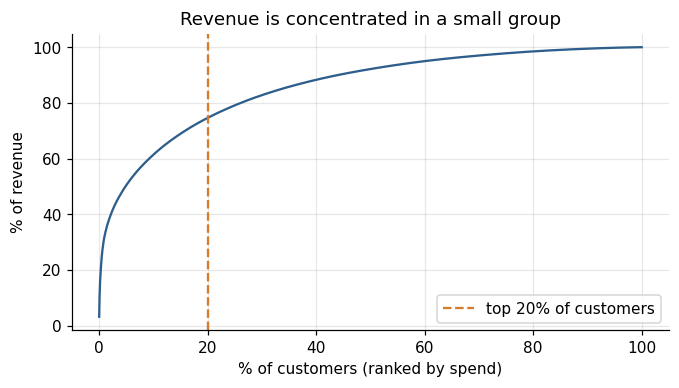

In [6]:
top20 = rev_by_cust.sort_values(ascending=False).head(int(len(rev_by_cust)*0.2))
print(f'top 20% of customers generate {top20.sum()/rev_by_cust.sum()*100:.1f}% of revenue')

cum = rev_by_cust.sort_values(ascending=False).cumsum() / rev_by_cust.sum() * 100
fig, ax = plt.subplots(figsize=(7,3.5))
ax.plot(np.arange(1, len(cum)+1)/len(cum)*100, cum.values, color='#2E5E8C')
ax.axvline(20, color='#D97A28', ls='--', label='top 20% of customers')
ax.set_xlabel('% of customers (ranked by spend)'); ax.set_ylabel('% of revenue')
ax.set_title('Revenue is concentrated in a small group'); ax.legend(); plt.show()

Losing a customer from the top of this curve costs far more than losing one from the bottom. Retention effort has to be **value-weighted**, which is exactly what Phase 8 does.

## 4. Revenue over time

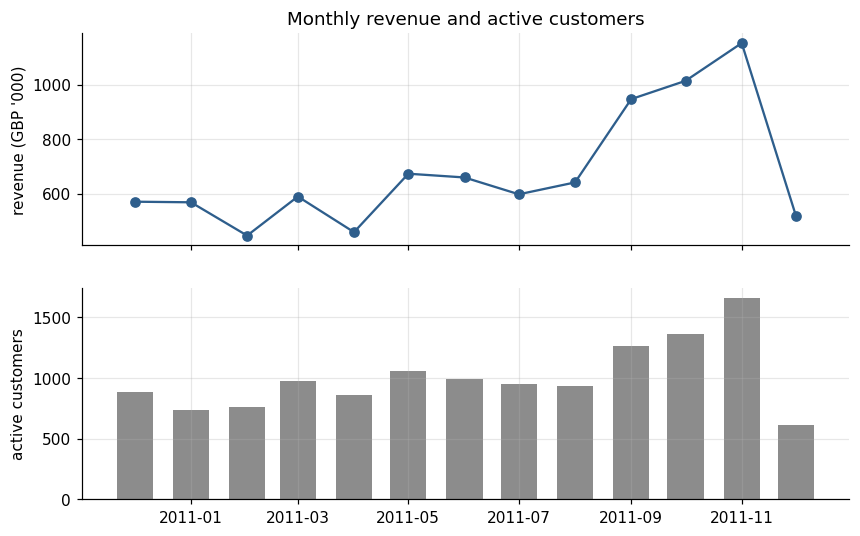

,revenue,orders,customers
InvoiceDate,,,
2010-12-01,570180.0,1397,884
2011-01-01,567992.0,984,739
2011-02-01,445660.0,993,757
2011-03-01,589169.0,1315,973
2011-04-01,458251.0,1141,855
2011-05-01,673037.0,1547,1054
2011-06-01,659275.0,1392,990
2011-07-01,597415.0,1325,947
2011-08-01,641062.0,1277,934


In [7]:
monthly = df.set_index('InvoiceDate').resample('MS').agg(
    revenue=('Revenue','sum'), orders=('InvoiceNo','nunique'), customers=('CustomerID','nunique'))
fig, ax = plt.subplots(2,1, figsize=(9,5.5), sharex=True)
ax[0].plot(monthly.index, monthly.revenue/1000, marker='o', color='#2E5E8C')
ax[0].set_ylabel("revenue (GBP '000)"); ax[0].set_title('Monthly revenue and active customers')
ax[1].bar(monthly.index, monthly.customers, width=20, color='#8C8C8C')
ax[1].set_ylabel('active customers'); plt.show()
monthly.round(0)

Revenue climbs steeply into November. December 2011 looks like a collapse but is
not - the data simply stops on 9 December. Any month-on-month comparison has to
account for that partial month.

## 5. How often do customers come back?

This sets the horizon for what counts as 'inactive'.

median gap between orders : 21 days
75th percentile           : 51 days
90th percentile           : 103 days


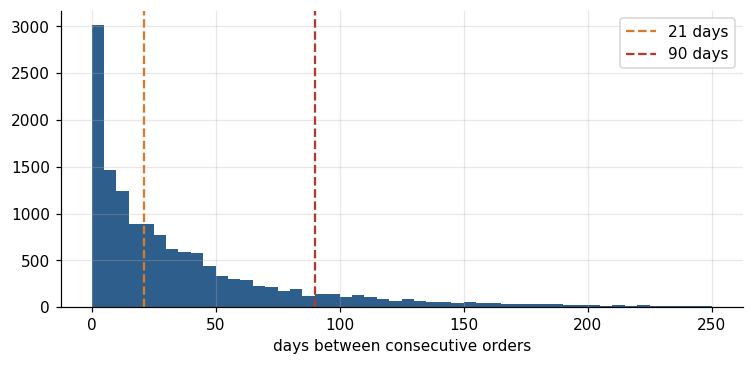

In [8]:
first_per_order = (df.groupby(['CustomerID','InvoiceNo']).InvoiceDate.min()
                   .reset_index().sort_values(['CustomerID','InvoiceDate']))
gaps = first_per_order.groupby('CustomerID').InvoiceDate.diff().dt.days.dropna()

print(f'median gap between orders : {gaps.median():.0f} days')
print(f'75th percentile           : {gaps.quantile(0.75):.0f} days')
print(f'90th percentile           : {gaps.quantile(0.90):.0f} days')

fig, ax = plt.subplots(figsize=(8,3.5))
ax.hist(gaps[gaps<=250], bins=50, color='#2E5E8C')
for d, c in [(21,'#D97A28'), (90,'#B03A2E')]:
    ax.axvline(d, color=c, ls='--', label=f'{d} days')
ax.set_xlabel('days between consecutive orders'); ax.legend(); plt.show()

### Why 90 days defines inactivity

A typical customer reorders after **21 days**, and 90% reorder within about 100
days. A customer silent for 90 days has therefore gone more than four times
their normal gap without buying - a meaningful signal, not just noise. This is
the evidence behind the 90-day prediction horizon.

## 6. Who has already gone quiet?

In [9]:
asof = df.InvoiceDate.max()
recency = (asof - df.groupby('CustomerID').InvoiceDate.max()).dt.days
print(f'as of {asof.date()}:')
for lo, hi, label in [(0,30,'Active (0-30d)'), (31,90,'Cooling (31-90d)'),
                      (91,180,'Dormant (91-180d)'), (181,10**4,'Lapsed (180d+)')]:
    m = (recency>=lo)&(recency<=hi)
    print(f'  {label:<22} {m.sum():>5,} customers   GBP {rev_by_cust[recency[m].index].sum():>12,.0f} historic revenue')

as of 2011-12-09:
  Active (0-30d)         1,693 customers   GBP    6,304,059 historic revenue
  Cooling (31-90d)       1,197 customers   GBP    1,505,464 historic revenue
  Dormant (91-180d)        584 customers   GBP      465,918 historic revenue
  Lapsed (180d+)           860 customers   GBP      558,183 historic revenue


Roughly a third of the customer base has not bought in over 90 days, holding about GBP 1.0m of historic revenue. The model's job is to spot the *next* group before they get here.

## 7. Products and geography

In [10]:
top_products = (df.groupby('Description')
    .agg(revenue=('Revenue','sum'), customers=('CustomerID','nunique'))
    .sort_values('revenue', ascending=False).head(10))
display(top_products.round(0))

geo = (df.groupby('Country').agg(revenue=('Revenue','sum'), customers=('CustomerID','nunique'))
       .sort_values('revenue', ascending=False))
geo['pct_revenue'] = (geo.revenue/geo.revenue.sum()*100).round(1)
display(geo.head(8).round(0))

,revenue,customers
Description,,
"PAPER CRAFT , LITTLE BIRDIE",168470.0,1
REGENCY CAKESTAND 3 TIER,142265.0,881
WHITE HANGING HEART T-LIGHT HOLDER,100392.0,856
JUMBO BAG RED RETROSPOT,85041.0,635
MEDIUM CERAMIC TOP STORAGE JAR,81417.0,138
POSTAGE,77804.0,331
PARTY BUNTING,68785.0,708
ASSORTED COLOUR BIRD ORNAMENT,56413.0,678
RABBIT NIGHT LIGHT,51251.0,450


,revenue,customers,pct_revenue
Country,,,
United Kingdom,7265021.0,3916,82.0
Netherlands,285446.0,9,3.0
EIRE,261888.0,3,3.0
Germany,226382.0,94,3.0
France,199442.0,87,2.0
Australia,138454.0,9,2.0
Spain,61559.0,30,1.0
Switzerland,56444.0,21,1.0


The UK is 82% of revenue and 90% of customers. The remaining countries are
small but include high-value wholesale accounts (Netherlands, EIRE, Germany).

**This is a UK business.** The methodology transfers to any e-commerce company,
but the numbers here describe a UK-based online gift retailer in 2010-2011.

## 8. Do cancellations say anything about a customer?

In [11]:
canc = load_cancellations()
canc_count = canc.groupby('CustomerID').InvoiceNo.nunique()
summary = pd.DataFrame({'orders': orders, 'cancels': canc_count}).fillna(0)
summary['revenue'] = rev_by_cust
print(summary.groupby(summary.cancels.clip(upper=3).astype(int))
      .agg(customers=('orders','size'), avg_orders=('orders','mean'),
           avg_revenue=('revenue','mean')).round(1))

         customers  avg_orders  avg_revenue
cancels                                    
0             2781         2.5        820.2
1              887         4.3       2058.3
2              308         5.9       3545.0
3              394        15.0       9429.0


Customers who cancel more also order more and spend more - cancelling is a sign
of an *active* wholesale relationship, not a disgruntled one. Worth keeping as a
feature, but its direction is the opposite of the obvious guess.

## Summary

| Finding | Number | Why it matters |
|---|---|---|
| Revenue from repeat customers | 93.0% | Retention is the main revenue lever |
| Repeat purchase rate | 65.5% | There is real loyalty to protect |
| Revenue from top 20% of customers | 74.6% | Effort must be value-weighted |
| Median gap between orders | 21 days | Justifies a 90-day inactivity horizon |
| Customers already 90+ days silent | 33.3% | A third of the base is already at risk |
| UK share of revenue | 82.2% | This is a UK business - state it honestly |